# Homework 7: Practicing Regression

### Part 1

Let's practice linear regression using a real estate dataset with information on home prices and other attributes like square footage and garage size.

In [1]:
# Import your libraries... 
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [2]:
# Check out the data... 
df = pd.read_csv('../regressions/data/real_estate_dataset.csv')
len(df)

500

In [3]:
df.head()

,ID,Square_Feet,Num_Bedrooms,Num_Bathrooms,Num_Floors,Year_Built,Has_Garden,Has_Pool,Garage_Size,Location_Score,Distance_to_Center,Price
0,1,143.635030,1,3,3,1967,1,1,48,8.297631,5.935734,602134.816747
1,2,287.678577,1,2,1,1949,0,1,37,6.061466,10.827392,591425.135386
2,3,232.998485,1,3,2,1923,1,0,14,2.911442,6.904599,464478.696880
3,4,199.664621,5,2,2,1918,0,0,17,2.070949,8.284019,583105.655996
4,5,89.004660,4,3,3,1999,1,0,34,1.523278,14.648277,619879.142523


Question: What factors explain differences in housing prices, and how well can we predict the price of a house using its characteristics?

Let's start simple with the question... Does house size affect price?

Fill in the blank: 
The independent variable in this analysis is house size. The dependent variable is price.
The regression formula is linear.


In [9]:
# Ok now let's perform the simple linear regression. Write your code below.

x = df["Square_Feet"]
y = df["Price"]

## use OLS to analyze 
model = sm.OLS(y,x)

results = model.fit()
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                  Price   R-squared (uncentered):                   0.893
Model:                            OLS   Adj. R-squared (uncentered):              0.893
Method:                 Least Squares   F-statistic:                              4172.
Date:                Sun, 08 Nov 2026   Prob (F-statistic):                   1.71e-244
Time:                        12:49:48   Log-Likelihood:                         -6798.4
No. Observations:                 500   AIC:                                  1.360e+04
Df Residuals:                     499   BIC:                                  1.360e+04
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Square_Feet  2960.4944     45.834     64.592      0.000    2870.444    3050.545
==============================================================================
Omnibus:                       33.308   Durbin-Watson:                   1.708
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               12.647
Skew:                          -0.077   Prob(JB):                      0.00179
Kurtosis:                       2.236   Cond. No.                         1.00
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Text(0, 0.5, 'Price (USD)')

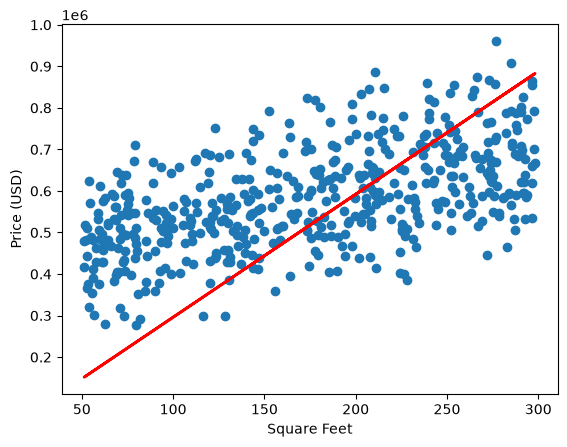

In [11]:
# Plot your data on a scatterplot and draft a regression line. Write your code below.

plt.scatter(df["Square_Feet"], df["Price"])
plt.plot(
    df["Square_Feet"], 
    results.predict(),
    color='red',
    linewidth=2,
    label='Regression Line'
)
##adding labels
plt.xlabel("Square Feet")
plt.ylabel("Price (USD)")

Ok, let's take it a step further. Our new question is: Does house size still matter when we control for the number of bedrooms and bathrooms?

Fill in the blank: 

The independent variable in this analysis is _sq feet________. 

The dependent variable is _price________. 

The control variables are __bed&bath______. 

The regression formula is __linear______. 

I'll help you with the code for the next part.

In [12]:
# Run multiple linear regression
model = smf.ols("Price ~ Square_Feet + Num_Bedrooms + Num_Bathrooms", data=df).fit()

# Display results
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.700
Model:                            OLS   Adj. R-squared:                  0.698
Method:                 Least Squares   F-statistic:                     385.7
Date:                Sun, 08 Nov 2026   Prob (F-statistic):          3.29e-129
Time:                        13:09:10   Log-Likelihood:                -6265.0
No. Observations:                 500   AIC:                         1.254e+04
Df Residuals:                     496   BIC:                         1.255e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept      2.055e+05   1.26e+04     16.270

Fill in the blank: 

Your model explains __70___% of the variation in house prices, and _3____ of my 3 explanatory variables are statistically significant.

When square footage is zero, the predicted house price is __954?___.

For every additional square foot, we can expect the predicted house price to increase by __40___ units, on average.


### Part 2

Read the main article in the Tampa Bay Times' Pulitzer Prize-winning series Failure Factories:\
https://projects.tampabay.com/projects/2015/investigations/pinellas-failure-factories/5-schools-segregation/

And then read the criticism of it in Forbes:\
https://www.forbes.com/sites/maureensullivan/2016/04/29/here-are-the-holes-in-the-pulitzer-winning-failure-factories-series-on-segregated-schools/

Answer the following questions (in at least 3 sentences each), which we will discuss further in class:

1. What are your thoughts on the Tampa Bay Times' series? What parts of it do you find valuable to readers?

2. The series got a scathing critique in Forbes. What are your thoughts on the critique? Do you find it compelling? What do you think the journalists at the Florida newsroom should have done differently? 

1. I think the article had some good topline stats (95% of Black students at the five schools are failing reading or math, more than half of teachers transfered out), they did make comparisons of passing rates to black students in other counties as a control. I did want them to share share of Black students in each county (are these predominately Black schools?). The poverty stats were also nice to create a baseline of what economic factors may be at play. But wowee are there a lot of assumptions of how Black children act in the classroom! And a lot of pointed language about state policy but not much about school policy, which I thought was interesting.

2. I think the Forbes article shows a lot more robust understanding of how schools work and what factors can influence a student's experience or likelihood of failing. The line about failing rates and how low-income and minority students are more likely to score lower on standardized tests is one clear example; a majority Black school has larger socioeconomic challenges at play than a majority White one and that's often reflected in test scores, not a result of a failing school. 